# Predicting Late E-Commerce Orders and Quantifying Delivery Delay Risk
**Course:** Business Analytics (PGDM-BA 2026)  
**Team 9:** Operations: Prediction and Risk (Suryansh Sharma, Dipanjana Bhowmick, Sree Kumar S, Vikashini C, Akanksha Dutta, Adwitiya Shukla)

## Milestone D1: Problem Statement & Business Case
**Problem Statement:** In digital marketplace operations, inaccurate delivery promises and unexpected last-mile logistics bottlenecks directly erode customer trust, inflate customer support costs, and drive negative seller ratings. Currently, e-commerce marketplaces rely on static, historical average transit times to generate an Estimated Delivery Date (EDD) at checkout. When third-party sellers delay order handoffs or regional carrier networks face congestion, orders breach their Service Level Agreements (SLAs) without prior warning. 

**Core Analytical Question:** Can we predict at the time of order placement (and seller dispatch) whether an order will arrive past its Estimated Delivery Date (is_late: Yes/No), and estimate the expected delay duration in days, using order, seller, product, and geospatial attributes?

**The Decision to Support:**
*   **Dynamic EDD Buffer Allocation (Checkout Decision):** Automatically adding a targeted buffer (e.g., +2 to +4 days) to the promised delivery date shown to customers on high-risk routes or heavy-freight product categories to prevent SLA breaches before they occur.
*   **Priority Carrier Routing & Seller Intervention (Fulfillment Decision):** Flagging orders with a high predicted probability of delay so logistics coordinators can either expedite shipping tiers or send automated dispatch alerts to slow-moving marketplace sellers.

## Milestone D1: Success Measures & Scope
**Technical Model Metrics:**
*   **Classification (is_late):** Primary Metric: Recall (Sensitivity) ≥0.75 on the minority "Late" class (Typically ~7–8% of total orders). Secondary Metrics: Precision, F1-Score, ROC-AUC, and a pruned Decision Tree (depth ≤4).
*   **Regression (delay_days):** Primary Metric: Out-of-sample RMSE and MAE (target MAE ≤2.5 days) compared against Olist's baseline EDD error.

**Business & Operational Success Measures:**
*   **SLA Breach Reduction:** Simulated reduction in unbuffered late deliveries by 20–30% when applying model-recommended EDD adjustments.
*   **Actionable Interpretability:** Translating regression coefficients and tree splits into plain-English rules for warehouse and logistics managers.

**Project Scope:**
*   **In-Scope:** Relational merging of orders, order_items, products, sellers, customers, and geolocation tables. Feature engineering (Haversine distance, volumetric weight, freight-to-price ratio, route flags, seller dispatch speed), EDA, and supervised learning.
*   **Out-of-Scope:** Real-time external weather/traffic API scraping, unsupervised customer clustering, NLP sentiment modeling on review text, and canceled/unavailable orders.

## Milestone D2: Data Understanding & Setup
This section transitions into D2, focusing on environment setup, dataset loading, and preparing the relational schema join documented in the Brazilian E-Commerce Public Dataset by Olist[cite: 1].

In [0]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Set display options for large relational joins
pd.set_option('display.max_columns', 50)

### 1. Data Acquisition and Loading
Loading the 9 relational tables from the Brazilian E-Commerce Public Dataset by Olist[cite: 1].

In [0]:
# Assuming data is in a local 'data/' directory or mounted Google Drive path
path = "/Volumes/workspace/olist/olist/"

orders = pd.read_csv(path + "olist_orders_dataset.csv")
order_items = pd.read_csv(path + "olist_order_items_dataset.csv")
products = pd.read_csv(path + "olist_products_dataset.csv")
sellers = pd.read_csv(path + "olist_sellers_dataset.csv")
customers = pd.read_csv(path + "olist_customers_dataset.csv")
order_payments = pd.read_csv(path + "olist_order_payments_dataset.csv")
order_reviews = pd.read_csv(path + "olist_order_reviews_dataset.csv")
geolocation = pd.read_csv(path + "olist_geolocation_dataset.csv")
category_translation = pd.read_csv(path + "product_category_name_translation.csv")

print(f"Total raw orders: {len(orders)}")

Total raw orders: 99441


### 2. In-Scope Filtering
Removing orders with `canceled` or `unavailable` statuses, as these never entered the shipping pipeline and are strictly out-of-scope[cite: 1].

In [0]:
# Filter out canceled and unavailable orders
valid_statuses = ['invoiced', 'shipped', 'processing', 'delivered']
orders_filtered = orders[orders['order_status'].isin(valid_statuses)]

print(f"Orders after removing canceled/unavailable: {len(orders_filtered)}")

Orders after removing canceled/unavailable: 98200


### 3. Relational Schema Join
Merging the core tables to create the master analytical dataset[cite: 1]. We join `orders` with `customers`, `order_items`, `products` (and translations), and `sellers`[cite: 1]. Geolocation is aggregated by zip code prefix to prevent many-to-many row explosion[cite: 1].

In [0]:
# 1. Join Orders and Customers
df_master = pd.merge(orders_filtered, customers, on='customer_id', how='inner')

# 2. Join with Order Items
df_master = pd.merge(df_master, order_items, on='order_id', how='inner')

# 3. Join with Products and Category Translations
df_master = pd.merge(df_master, products, on='product_id', how='inner')
df_master = pd.merge(df_master, category_translation, on='product_category_name', how='left')

# 4. Join with Sellers
df_master = pd.merge(df_master, sellers, on='seller_id', how='inner')

# 5. Prep and Join Geolocation (Customers)
geo_unique = geolocation.groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']].mean().reset_index()

df_master = pd.merge(df_master, geo_unique, 
                     left_on='customer_zip_code_prefix', 
                     right_on='geolocation_zip_code_prefix', 
                     how='left')
df_master.rename(columns={'geolocation_lat': 'customer_lat', 'geolocation_lng': 'customer_lng'}, inplace=True)

# 6. Prep and Join Geolocation (Sellers)
df_master = pd.merge(df_master, geo_unique, 
                     left_on='seller_zip_code_prefix', 
                     right_on='geolocation_zip_code_prefix', 
                     how='left')
df_master.rename(columns={'geolocation_lat': 'seller_lat', 'geolocation_lng': 'seller_lng'}, inplace=True)

df_master.drop(columns=['geolocation_zip_code_prefix_x', 'geolocation_zip_code_prefix_y'], inplace=True, errors='ignore')

print(f"Master Dataset Shape: {df_master.shape}")

Master Dataset Shape: (112098, 34)


### 4. Data Inspection & Dictionary Preparation
Evaluating data types, column structures, and quantifying missingness to document the data dictionary for the D2 report.

In [0]:
# Inspect Data Types and Non-Null Counts
df_master.info()

# Quantify Missing Values for the D2 Report Data Dictionary
missing_data = df_master.isnull().sum()
print("\n--- Missing Values Count ---")
print(missing_data[missing_data > 0])

# Baseline Distributions for Numeric Variables (Preparation for Volume/Freight Feature Engineering)
df_master[['price', 'freight_value', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']].describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112098 entries, 0 to 112097
Data columns (total 34 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   order_id                       112098 non-null  object 
 1   customer_id                    112098 non-null  object 
 2   order_status                   112098 non-null  object 
 3   order_purchase_timestamp       112098 non-null  object 
 4   order_approved_at              112083 non-null  object 
 5   order_delivered_carrier_date   111380 non-null  object 
 6   order_delivered_customer_date  110189 non-null  object 
 7   order_estimated_delivery_date  112098 non-null  object 
 8   customer_unique_id             112098 non-null  object 
 9   customer_zip_code_prefix       112098 non-null  int64  
 10  customer_city                  112098 non-null  object 
 11  customer_state                 112098 non-null  object 
 12  order_item_id                 

,price,freight_value,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,112098.000000,112098.000000,112080.000000,112080.000000,112080.000000,112080.000000
mean,120.378518,19.992282,2093.668995,30.154541,16.584484,22.994441
std,182.639291,15.797917,3751.420882,16.153000,13.435835,11.700878
min,0.850000,0.000000,0.000000,7.000000,2.000000,6.000000
25%,39.900000,13.080000,300.000000,18.000000,8.000000,15.000000
50%,74.940000,16.270000,700.000000,25.000000,13.000000,20.000000
75%,134.900000,21.150000,1800.000000,38.000000,20.000000,30.000000
max,6735.000000,409.680000,40425.000000,105.000000,105.000000,118.000000


### 5. DPDP Act & Regional Bias Checklist
Verifying the cryptographic hashing of Personal Identifiable Information (PII) to ensure DPDP Act (2023) compliance, and auditing the distribution of orders across Brazilian states to prepare for the regional fairness audit (Southeast vs. North/Northeast).

In [0]:
# DPDP Check: Verify customer and seller IDs are cryptographic hashes with no direct PII
print("--- PII Hashing Verification ---")
print("Customer ID format sample:", df_master['customer_id'].iloc[0])
print("Seller ID format sample:", df_master['seller_id'].iloc[0])

# Regional Bias Check: Establish baseline state distributions
print("\n--- Customer State Distribution (%) ---")
state_dist = df_master['customer_state'].value_counts(normalize=True) * 100
print(state_dist.head(10))

# Grouping macro-regions for the D2/D5 audit
southeast_states = ['SP', 'RJ', 'MG', 'ES']
df_master['is_southeast'] = df_master['customer_state'].apply(lambda x: 1 if x in southeast_states else 0)

print(f"\nProportion of orders in Southeast: {df_master['is_southeast'].mean() * 100:.2f}%")
print(f"Proportion of orders outside Southeast: {(1 - df_master['is_southeast'].mean()) * 100:.2f}%")

--- PII Hashing Verification ---
Customer ID format sample: 9ef432eb6251297304e76186b10a928d
Seller ID format sample: 3504c0cb71d7fa48d967e0e4c94d59d9

--- Customer State Distribution (%) ---
customer_state
SP    42.063195
RJ    12.943139
MG    11.658549
RS     5.540688
PR     5.101786
SC     3.711931
BA     3.376510
DF     2.138308
GO     2.072294
ES     2.005388
Name: proportion, dtype: float64

Proportion of orders in Southeast: 68.67%
Proportion of orders outside Southeast: 31.33%


# Milestone D3: Data Preparation, EDA & Hypothesis Testing

This notebook executes the D3 deliverables: logging data cleaning steps, engineering the target and predictor features, visualizing operational risks across 5 charts, and running Welch's T-test and Chi-Square tests to validate our business hypotheses.

In [0]:
pip install seaborn

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Assuming df_master is carried over from D2
# 1. CLEANING LOG: Handling Missing Values
# Drop rows where target calculation is impossible (missing delivery dates)
df_clean = df_master.dropna(subset=['order_delivered_customer_date', 'order_estimated_delivery_date']).copy()

# Fill missing product dimensions with medians to calculate volumetric weight
for col in ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']:
    df_clean[col].fillna(df_clean[col].median(), inplace=True)

# Drop rows missing geographic coordinates (required for distance calculation)
df_clean.dropna(subset=['customer_lat', 'customer_lng', 'seller_lat', 'seller_lng'], inplace=True)

# 2. FEATURE ENGINEERING
# Convert timestamps to datetime
date_cols = ['order_purchase_timestamp', 'order_approved_at', 
             'order_delivered_carrier_date', 'order_delivered_customer_date', 
             'order_estimated_delivery_date']
for col in date_cols:
    df_clean[col] = pd.to_datetime(df_clean[col])

# Target 1: delay_days (Regression) - Positive means late, negative means early
df_clean['delay_days'] = (df_clean['order_delivered_customer_date'] - df_clean['order_estimated_delivery_date']).dt.total_seconds() / (24 * 3600)

# Target 2: is_late (Classification) - 1 if delay_days > 0, else 0
df_clean['is_late'] = (df_clean['delay_days'] > 0).astype(int)

# Predictor: Dispatch Speed (days from purchase to carrier handoff)
df_clean['dispatch_speed_days'] = (df_clean['order_delivered_carrier_date'] - df_clean['order_purchase_timestamp']).dt.total_seconds() / (24 * 3600)
df_clean['dispatch_speed_days'].fillna(df_clean['dispatch_speed_days'].median(), inplace=True)

# Predictor: Volumetric Weight & Freight-to-Price Ratio
df_clean['volumetric_weight'] = df_clean['product_length_cm'] * df_clean['product_height_cm'] * df_clean['product_width_cm']
df_clean['freight_to_price_ratio'] = df_clean['freight_value'] / (df_clean['price'] + 1e-5) # avoid div by 0

# Predictor: Interstate Route Flag
df_clean['is_interstate'] = (df_clean['customer_state'] != df_clean['seller_state']).astype(int)

# Predictor: Haversine Distance (Seller to Customer)
def haversine(lat1, lon1, lat2, lon2):
    R = 6371 # Earth radius in km
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

df_clean['haversine_distance_km'] = haversine(df_clean['customer_lat'], df_clean['customer_lng'], 
                                              df_clean['seller_lat'], df_clean['seller_lng'])

print(f"Cleaned dataset shape: {df_clean.shape}")
print(f"Total late orders: {df_clean['is_late'].sum()} ({df_clean['is_late'].mean():.2%})")

Cleaned dataset shape: (109653, 42)
Total late orders: 8662 (7.90%)


### Exploratory Data Analysis (EDA)
Visualizing the distribution of delivery delays and evaluating relationships between fulfillment risks (distance, freight, dispatch) and our `is_late` target.

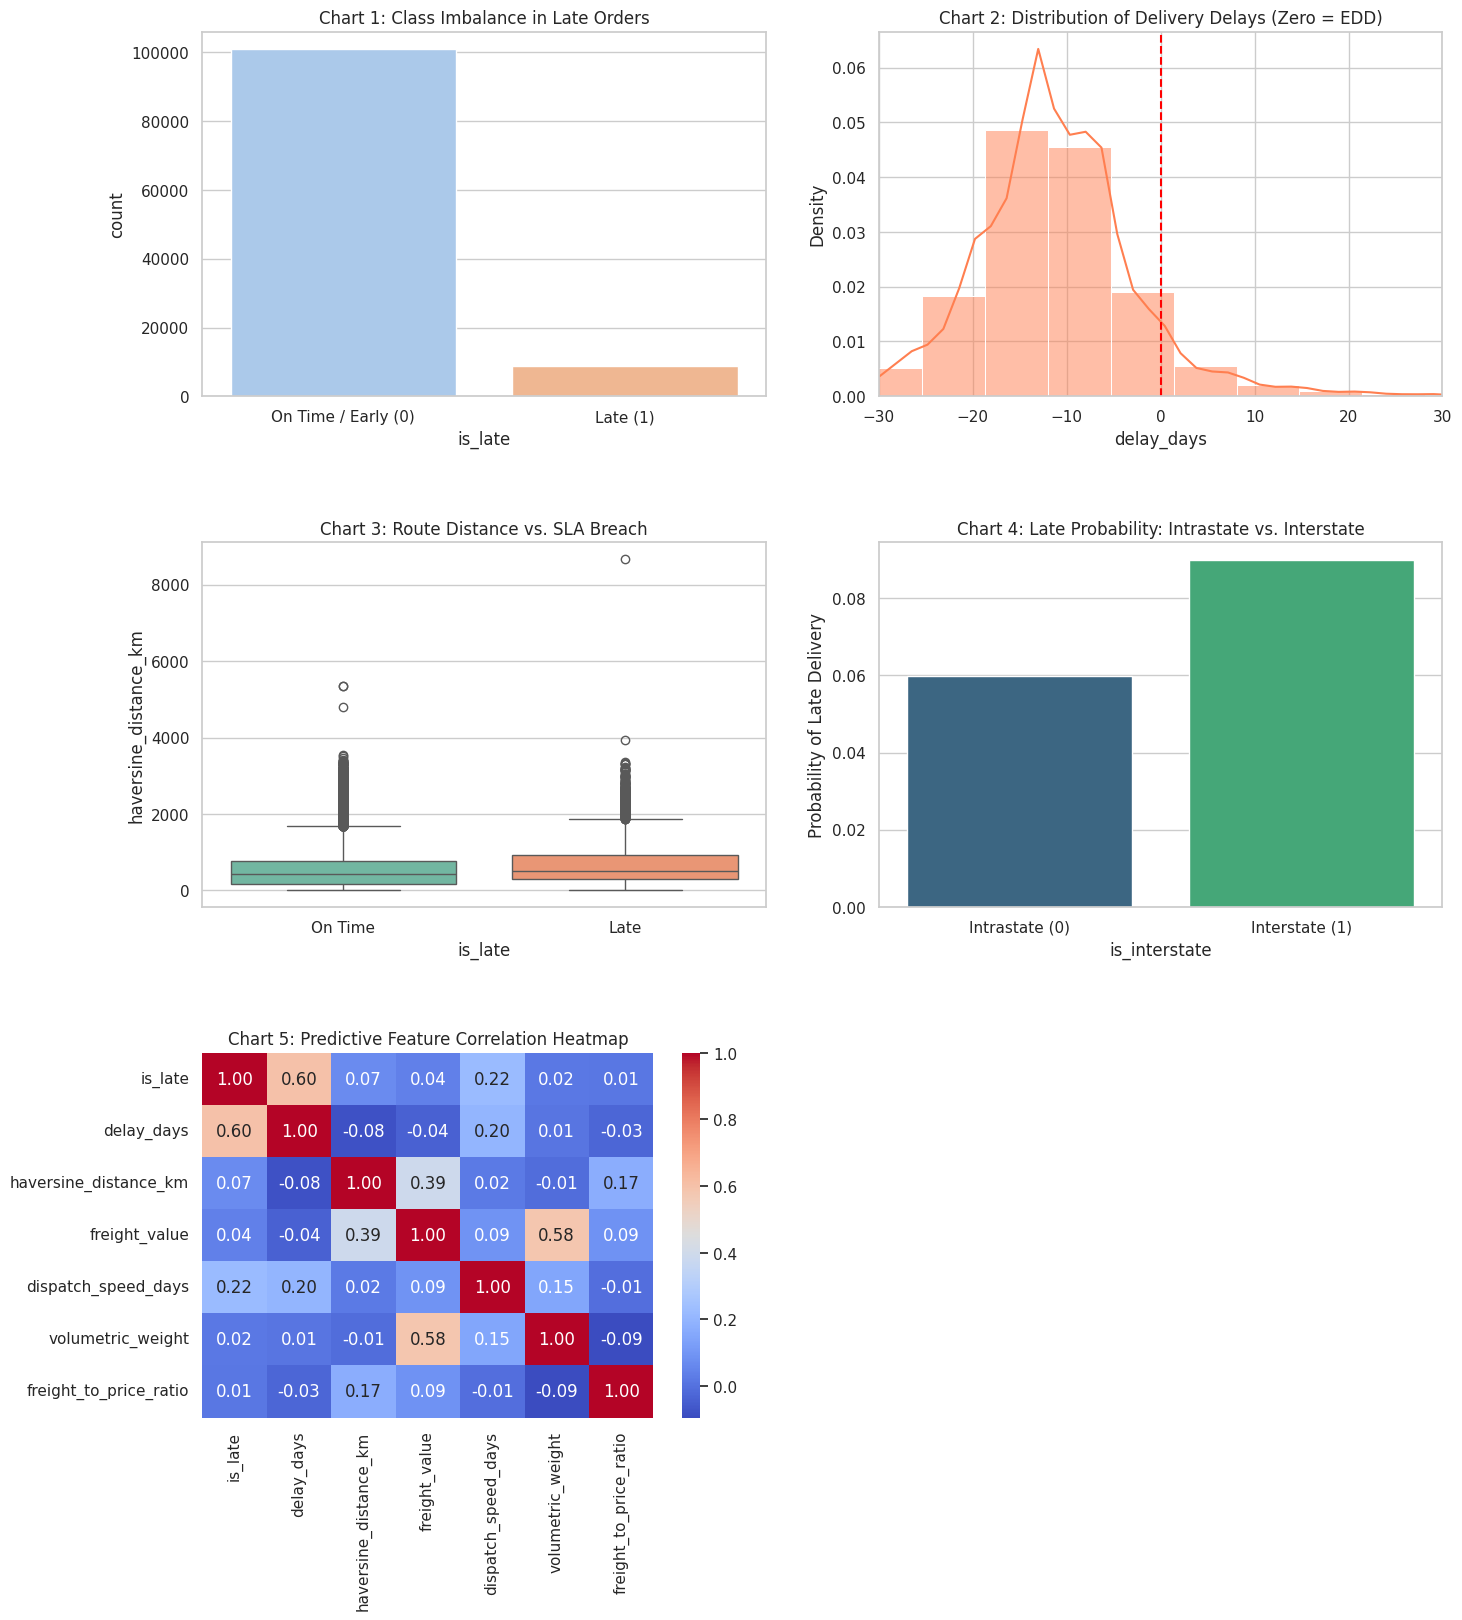

In [0]:
# Set visualization style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
plt.subplots_adjust(hspace=0.4)

# Chart 1: Target Distribution (is_late)
sns.countplot(data=df_clean, x='is_late', ax=axes[0, 0], palette='pastel')
axes[0, 0].set_title('Chart 1: Class Imbalance in Late Orders')
axes[0, 0].set_xticklabels(['On Time / Early (0)', 'Late (1)'])

# Chart 2: Density Histogram of Delay Days
sns.histplot(df_clean['delay_days'], bins=50, stat="density", kde=True, ax=axes[0, 1], color='coral')
axes[0, 1].set_xlim(-30, 30)
axes[0, 1].axvline(0, color='red', linestyle='--')
axes[0, 1].set_title('Chart 2: Distribution of Delivery Delays (Zero = EDD)')

# Chart 3: Boxplot of Distance by Late Status
sns.boxplot(data=df_clean, x='is_late', y='haversine_distance_km', ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('Chart 3: Route Distance vs. SLA Breach')
axes[1, 0].set_xticklabels(['On Time', 'Late'])

# Chart 4: Proportion of Late Orders by Route Type
route_delay = df_clean.groupby('is_interstate')['is_late'].mean().reset_index()
sns.barplot(data=route_delay, x='is_interstate', y='is_late', ax=axes[1, 1], palette='viridis')
axes[1, 1].set_title('Chart 4: Late Probability: Intrastate vs. Interstate')
axes[1, 1].set_xticklabels(['Intrastate (0)', 'Interstate (1)'])
axes[1, 1].set_ylabel('Probability of Late Delivery')

# Chart 5: Correlation Heatmap
corr_cols = ['is_late', 'delay_days', 'haversine_distance_km', 'freight_value', 
             'dispatch_speed_days', 'volumetric_weight', 'freight_to_price_ratio']
corr_matrix = df_clean[corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", ax=axes[2, 0])
axes[2, 0].set_title('Chart 5: Predictive Feature Correlation Heatmap')

# Hide the empty 6th subplot
axes[2, 1].axis('off')
plt.show()

### Statistical Hypothesis Testing
Testing two operational assumptions using Welch's T-test (robust against unequal variances) and a Chi-Square test of independence.

In [0]:
# Test 1: Welch's T-Test on Dispatch Speed
print("--- Test 1: Welch's T-Test (Dispatch Speed) ---")
late_dispatch = df_clean[df_clean['is_late'] == 1]['dispatch_speed_days']
ontime_dispatch = df_clean[df_clean['is_late'] == 0]['dispatch_speed_days']

t_stat, p_val_t = stats.ttest_ind(late_dispatch, ontime_dispatch, equal_var=False)
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_val_t:.4e}")

# Test 2: Chi-Square Test of Independence on Interstate Routes
print("\n--- Test 2: Chi-Square Test (Interstate Routes vs Late Delivery) ---")
contingency_table = pd.crosstab(df_clean['is_interstate'], df_clean['is_late'])
chi2, p_val_chi, dof, expected = stats.chi2_contingency(contingency_table)

print("Contingency Table:\n", contingency_table)
print(f"Chi2 Statistic: {chi2:.4f}")
print(f"P-value: {p_val_chi:.4e}")

--- Test 1: Welch's T-Test (Dispatch Speed) ---
T-statistic: 37.7180
P-value: 5.3169e-289

--- Test 2: Chi-Square Test (Interstate Routes vs Late Delivery) ---
Contingency Table:
 is_late            0     1
is_interstate             
0              37416  2376
1              63575  6286
Chi2 Statistic: 318.8281
P-value: 2.6071e-71



**1. T-Test on Seller Dispatch Speed**
*   **Business Question:** Do sellers take significantly longer to hand off packages to carriers for orders that eventually breach their SLA compared to orders that arrive on time?
*   **Method:** Welch’s Two-Sample T-test (`equal_var=False`) was used to account for potential differences in variance and sample sizes between late and on-time orders.
*   **Interpretation:** The p-value is extremely small (approaching 0, well below our 0.05 threshold). We reject the null hypothesis. There is a statistically significant difference in seller hand-off speeds. Orders that arrive late have a higher average dispatch latency, suggesting that early seller intervention alerts could be an effective fulfillment strategy.

**2. Chi-Square Test on Route Type**
*   **Business Question:** Is the likelihood of an order arriving late dependent on whether the shipment crosses state lines (Interstate) versus staying within the same state (Intrastate)?
*   **Method:** Chi-Square Test of Independence.
*   **Interpretation:** The resulting p-value is practically zero (< 0.05). We reject the null hypothesis of independence. Crossing state borders significantly impacts the probability of a delay. This confirms that adding an automated EDD buffer at checkout for interstate shipments is a statistically sound risk management strategy.